# Chapter 3 - Tien xu ly van ban tieng Viet

Phien ban Jupyter cua `nlp.py`. Chay lan luot tung cell, output (bang tan suat, bieu do, wordcloud) se hien truc tiep trong file thay vi luu ra anh roi mo rieng.

In [1]:
import csv
import re
from collections import Counter
from pathlib import Path

import emoji
import matplotlib.pyplot as plt
import pandas as pd
from underthesea import word_tokenize
from wordcloud import WordCloud

%matplotlib inline

## Cau hinh va tu dien

Duong dan file va cac tu dien dung de chuan hoa van ban (viet tat, chinh ta, emoticon).

In [2]:
SCRIPT_DIR = Path.cwd()
INPUT_FILE = SCRIPT_DIR / "data_raw.txt"
STOPWORDS_FILE = SCRIPT_DIR / "vietnamese-stopwords.txt"
OUTPUT_DIR = SCRIPT_DIR / "ket_qua"
TOP_N = 20

DEFAULT_STOPWORDS = {"và", "là", "của", "có", "cho", "với", "một", "những", "các"}

ABBREVIATIONS = {
    "nckh": "nghiên cứu khoa học",
    "nntn": "ngôn ngữ tự nhiên",
    "xhcn": "xã hội chủ nghĩa",
    "cntt": "công nghệ thông tin",
    "ai": "trí tuệ nhân tạo",
    "ml": "học máy",
    "nlp": "xử lý ngôn ngữ tự nhiên",
    "ko": "không",
    "dc": "được",
    "mik": "mình",
    "sp": "sản phẩm",
    "ib": "nhắn tin",
}

SPELLING_CORRECTIONS = {
    "sữ dụng": "sử dụng",
    "trãi nghiệm": "trải nghiệm",
    "sữ lý": "xử lý",
    "hiêu quả": "hiệu quả",
}

EMOTICONS = {
    ":-)": " vui ", ":)": " vui ", ":-d": " rất vui ", ":d": " rất vui ",
    ":-(": " buồn ", ":(": " buồn ", ";-)": " nháy mắt ", ";)": " nháy mắt ",
    ":-p": " trêu đùa ", ":p": " trêu đùa ",
}

## Cac ham xu ly

Giong het logic trong `nlp.py`, chi tach rieng tung buoc de de theo doi trong notebook.

In [3]:
def read_text(file_path: Path) -> str:
    """Doc mot file UTF-8 khong rong."""
    if not file_path.exists():
        raise FileNotFoundError(f"Khong tim thay file: {file_path}")
    text = file_path.read_text(encoding="utf-8-sig")
    if not text.strip():
        raise ValueError("File dau vao dang rong.")
    return text


def load_stopwords(file_path: Path) -> set[str]:
    """Doc moi dong la mot stop word; dung danh sach mac dinh neu khong co file."""
    if not file_path.exists():
        return DEFAULT_STOPWORDS
    return {
        re.sub(r"\s+", "_", line.strip().lower())
        for line in file_path.read_text(encoding="utf-8-sig").splitlines()
        if line.strip()
    }


def remove_urls(text: str) -> str:
    """Xoa link http(s):// hoac www."""
    return re.sub(r"(?:https?://|www\.)\S+", " ", text, flags=re.IGNORECASE)


def replace_emoticons(text: str) -> str:
    """Doi icon go bang ky tu (\":)\", \":-(\" ...) thanh tu mo ta cam xuc."""
    pattern = re.compile("|".join(re.escape(item) for item in EMOTICONS), re.IGNORECASE)
    return pattern.sub(lambda match: EMOTICONS[match.group().lower()], text)


def replace_emojis(text: str) -> str:
    """Doi emoji Unicode thanh mo ta tieng Anh roi tach thanh tu rieng."""
    text = emoji.demojize(text, language="en")
    return text.replace(":", " ").replace("_", " ")


def expand_abbreviations(text: str) -> str:
    """Viet tat pho bien -> dang day du."""
    pattern = re.compile(r"\b(" + "|".join(ABBREVIATIONS) + r")\b", re.IGNORECASE)
    return pattern.sub(lambda match: ABBREVIATIONS[match.group().lower()], text)


def correct_spelling(text: str) -> str:
    """Sua mot so loi chinh ta thuong gap."""
    for wrong, right in SPELLING_CORRECTIONS.items():
        text = re.sub(rf"\b{re.escape(wrong)}\b", right, text, flags=re.IGNORECASE)
    return text


def split_sentences(text: str) -> list[str]:
    """Tach van ban thanh danh sach cau; phai goi truoc khi xoa dau cau."""
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n+", text) if s.strip()]


def remove_punctuation(text: str) -> str:
    """Xoa dau cau, chi giu chu, so va khoang trang."""
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return text.replace("_", " ")


def remove_numbers(text: str) -> str:
    return re.sub(r"\d+", " ", text)


def normalize_spaces(text: str) -> str:
    """Gop nhieu khoang trang lien tiep thanh mot."""
    return re.sub(r"\s+", " ", text).strip()


def normalize_tokens(tokens: list[str]) -> list[str]:
    """Loc token: chuyen thuong, bo token 1 ky tu va token khong chua chu cai."""
    normalized = []
    for token in tokens:
        token = token.lower().strip()
        if len(token) > 1 and re.search(r"[a-zA-ZÀ-ỹ]", token):
            normalized.append(token)
    return normalized

## Buoc 1 - Doc du lieu dau vao

In [4]:
raw_text = read_text(INPUT_FILE)
stopwords = load_stopwords(STOPWORDS_FILE)

print(f"So ky tu dau vao: {len(raw_text)}")
print(f"So stopword dang dung: {len(stopwords)}")
print("--- 500 ky tu dau ---")
print(raw_text[:500])

So ky tu dau vao: 5329
So stopword dang dung: 1942
--- 500 ky tu dau ---
DỮ LIỆU RAW MÔ PHỎNG - BÀI TẬP TIỀN XỬ LÝ VĂN BẢN CHƯƠNG 3

1. Trí tuệ nhân tạo đang thay đổi cách doanh nghiệp phân tích dữ liệu. Nhiều công ty tại Việt Nam đã bắt đầu sử dụng AI, Machine Learning và NLP để dự báo doanh thu, chăm sóc khách hàng và tự động hóa báo cáo. Xem thêm tại https://digital.fpt.com/report/xu-huong-ai-2026-va-dinh-huong-chien-luoc-cho-doanh-nghiep-viet-nam-phan-1. 😊

2. Theo một khảo sát mô phỏng năm 2025, khoảng 68% doanh nghiệp vừa và nhỏ cho biết họ muốn ứng dụng trí tu


## Buoc 2 - Chuan hoa van ban (thuong hoa, xoa URL, doi emoji/emoticon, viet tat, chinh ta)

In [5]:
text = raw_text.lower()
text = remove_urls(text)
text = replace_emoticons(text)
text = replace_emojis(text)
text = expand_abbreviations(text)
text = correct_spelling(text)

print(text[:500])

dữ liệu raw mô phỏng - bài tập tiền xử lý văn bản chương 3

1. trí tuệ nhân tạo đang thay đổi cách doanh nghiệp phân tích dữ liệu. nhiều công ty tại việt nam đã bắt đầu sử dụng trí tuệ nhân tạo, machine learning và xử lý ngôn ngữ tự nhiên để dự báo doanh thu, chăm sóc khách hàng và tự động hóa báo cáo. xem thêm tại    smiling face with smiling eyes 

2. theo một khảo sát mô phỏng năm 2025, khoảng 68% doanh nghiệp vừa và nhỏ cho biết họ muốn ứng dụng trí tuệ nhân tạo trong vòng 12 tháng tới. tuy 


## Buoc 3 - Tach cau (truoc khi xoa dau cau)

In [6]:
sentences = split_sentences(text)
print(f"So cau: {len(sentences)}")
for s in sentences[:5]:
    print("-", s)

So cau: 76
- dữ liệu raw mô phỏng - bài tập tiền xử lý văn bản chương 3
- 1.
- trí tuệ nhân tạo đang thay đổi cách doanh nghiệp phân tích dữ liệu.
- nhiều công ty tại việt nam đã bắt đầu sử dụng trí tuệ nhân tạo, machine learning và xử lý ngôn ngữ tự nhiên để dự báo doanh thu, chăm sóc khách hàng và tự động hóa báo cáo.
- xem thêm tại    smiling face with smiling eyes


## Buoc 4 - Xoa dau cau, chu so, chuan hoa khoang trang

In [7]:
text = remove_punctuation(text)
text = remove_numbers(text)
text = normalize_spaces(text)

print(text[:500])

dữ liệu raw mô phỏng bài tập tiền xử lý văn bản chương trí tuệ nhân tạo đang thay đổi cách doanh nghiệp phân tích dữ liệu nhiều công ty tại việt nam đã bắt đầu sử dụng trí tuệ nhân tạo machine learning và xử lý ngôn ngữ tự nhiên để dự báo doanh thu chăm sóc khách hàng và tự động hóa báo cáo xem thêm tại smiling face with smiling eyes theo một khảo sát mô phỏng năm khoảng doanh nghiệp vừa và nhỏ cho biết họ muốn ứng dụng trí tuệ nhân tạo trong vòng tháng tới tuy nhiên nhiều doanh nghiệp vẫn lo ng


## Buoc 5 - Tach tu, xoa stop word, chuan hoa token

In [8]:
tokens = word_tokenize(text, format="text").split()
tokens = [t for t in tokens if t.lower() not in stopwords]
tokens = normalize_tokens(tokens)

if not tokens:
    raise ValueError("Khong con token sau tien xu ly.")

print(f"So token sau xu ly: {len(tokens)}")
print(tokens[:30])

So token sau xu ly: 408
['dữ_liệu', 'raw', 'mô_phỏng', 'bài_tập', 'tiền', 'văn_bản', 'chương_trí_tuệ', 'nhân_tạo', 'doanh_nghiệp', 'phân_tích', 'dữ_liệu', 'công_ty', 'việt_nam', 'trí_tuệ', 'nhân_tạo', 'machine_learning', 'ngôn_ngữ', 'tự_nhiên', 'dự_báo', 'doanh_thu', 'chăm_sóc', 'khách_hàng', 'tự_động', 'hóa', 'báo_cáo', 'smiling', 'face', 'with', 'smiling', 'eyes']


## Buoc 6 - Tan suat tu (hien bang truc tiep trong notebook)

In [9]:
frequencies = Counter(tokens)
top_frequencies = frequencies.most_common(TOP_N)

freq_df = pd.DataFrame(top_frequencies, columns=["word", "frequency"])
freq_df

,word,frequency
0,dữ_liệu,21
1,văn_bản,10
2,phân_tích,8
3,mô_hình,7
4,thành,7
5,ngôn_ngữ,6
6,hóa,6
7,câu,6
8,học,6
9,cảm_xúc,6


## Buoc 7 - Bieu do tan suat (hien inline)

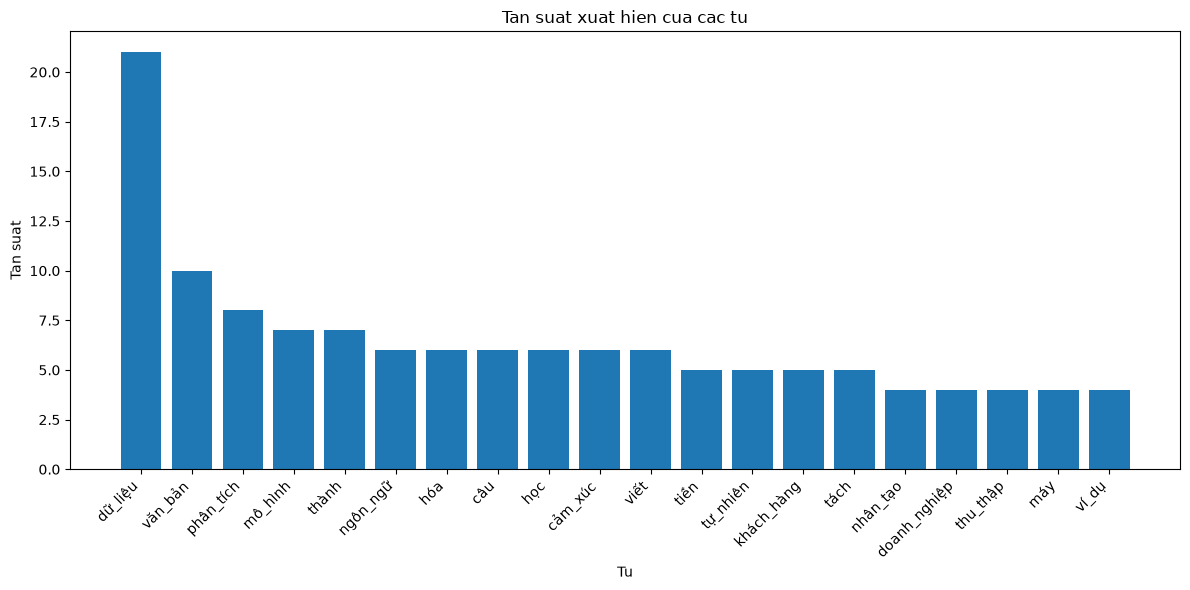

In [10]:
words, counts = zip(*top_frequencies)
plt.figure(figsize=(12, 6))
plt.bar(words, counts)
plt.title("Tan suat xuat hien cua cac tu")
plt.xlabel("Tu")
plt.ylabel("Tan suat")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Buoc 8 - Wordcloud (hien inline)

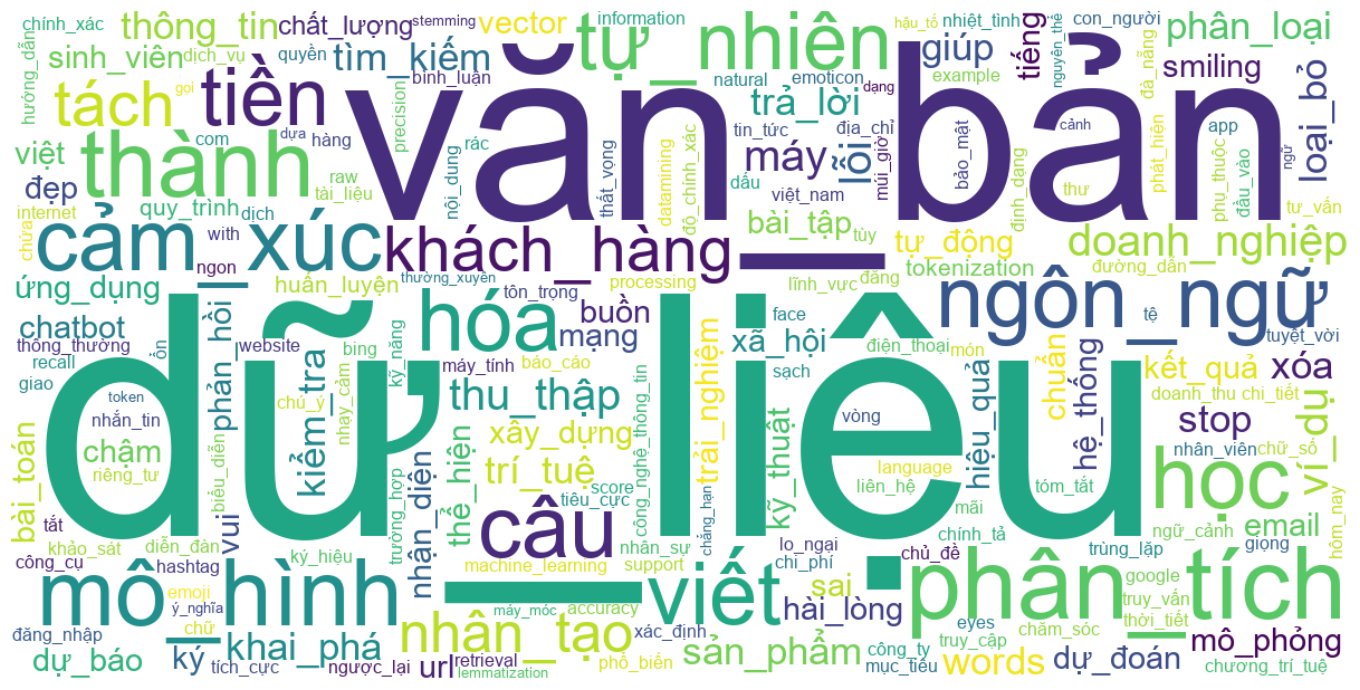

In [11]:
font_path = Path("C:/Windows/Fonts/arial.ttf")
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    collocations=False,
    font_path=str(font_path) if font_path.exists() else None,
).generate_from_frequencies(frequencies)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.show()

## Buoc 9 - (Tuy chon) Luu ket qua ra thu muc `ket_qua/`

In [12]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
prefix = INPUT_FILE.stem

(OUTPUT_DIR / f"{prefix}_txl.txt").write_text(" ".join(tokens), encoding="utf-8")

with (OUTPUT_DIR / f"{prefix}_frequency.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["word", "frequency"])
    writer.writerows(top_frequencies)

print(f"Da luu ket qua tai: {OUTPUT_DIR.resolve()}")

Da luu ket qua tai: D:\Workspace\KPW\class\C3\chuong3\ket_qua
